# 03 — Financial Risk Analysis



In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

def show(markdown_text):
    display(Markdown(markdown_text))

candidate_paths = [
    Path("../data/raw/data_FraudDetection_JAR2020.csv"),
    Path("data/raw/data_FraudDetection_JAR2020.csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not locate data_FraudDetection_JAR2020.csv in either "
        f"{candidate_paths[0]} or {candidate_paths[1]}."
    )

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()  # working copy; df_raw is never modified below

TARGET = "misstate"
ID_VARS = ["gvkey", "fyear"]
LABEL_META_VARS = ["p_aaer"]
RAW_VARS = ["act","ap","at","ceq","che","cogs","csho","dlc","dltis","dltt","dp","ib",
            "invt","ivao","ivst","lct","lt","ni","ppegt","pstk","re","rect","sale","sstk",
            "txp","txt","xint","prcc_f"]
RATIO_VARS = ["dch_wc","ch_rsst","dch_rec","dch_inv","soft_assets","ch_cs","ch_cm",
              "ch_roa","issue","bm","dpi","reoa","EBIT","ch_fcf"]

# Per Notebook 2, Section 6: convert any +/-inf to NaN (none were found in the original
# file, but this keeps the notebook consistent and reproducible if the source changes).
for c in RAW_VARS + RATIO_VARS:
    s = df[c].astype(float)
    if np.isinf(s).any():
        df[c] = s.replace([np.inf, -np.inf], np.nan)

show(f"**Loaded:** `{DATA_PATH}`  \n**Shape:** {df.shape[0]:,} rows x {df.shape[1]} columns")


**Loaded:** `..\data\raw\data_FraudDetection_JAR2020.csv`  
**Shape:** 146,045 rows x 46 columns

In [2]:
required_cols = ID_VARS + [TARGET] + LABEL_META_VARS + RAW_VARS + RATIO_VARS
missing_required = [c for c in required_cols if c not in df.columns]

checks = {
    "Shape": f"{df.shape[0]:,} rows x {df.shape[1]} columns",
    "Target distribution": df[TARGET].value_counts().to_dict(),
    "Positive rate (%)": round(df[TARGET].mean() * 100, 4),
    "Unique companies (gvkey)": df["gvkey"].nunique(),
    "Fiscal year range": f"{df['fyear'].min()}-{df['fyear'].max()}",
    "Duplicate (gvkey, fyear) rows": int(df.duplicated(subset=["gvkey", "fyear"]).sum()),
    "Missing required columns": missing_required if missing_required else "None",
}
for k, v in checks.items():
    show(f"**{k}:** {v}")

assert not missing_required, f"Missing required columns: {missing_required}"
assert df.duplicated(subset=['gvkey', 'fyear']).sum() == 0, "Unexpected duplicate (gvkey, fyear) rows."
assert set(df[TARGET].unique()).issubset({0, 1}), "Target contains unexpected values."
assert len(df) == 146045, "Row count differs from the value established in Notebooks 1-2 — investigate before proceeding."
show("**All Phase 2 continuity checks passed.**")


**Shape:** 146,045 rows x 46 columns

**Target distribution:** {0: 145081, 1: 964}

**Positive rate (%):** 0.6601

**Unique companies (gvkey):** 18444

**Fiscal year range:** 1990-2014

**Duplicate (gvkey, fyear) rows:** 0

**Missing required columns:** None

**All Phase 2 continuity checks passed.**

In [3]:
risk_framework = pd.DataFrame([
    ("A. Working Capital & Liquidity Risk", "dch_wc, ch_rsst, act, lct",
     "Captures the direction and scale of working-capital and net-operating-asset changes.",
     "Large or unusual working-capital accrual growth is a theorized earnings-management channel (Dechow et al. 2011)."),
    ("B. Revenue / Receivables Risk", "dch_rec, ch_cs, ch_cm, sale, rect",
     "Captures receivables growth relative to sales and changes in cash-basis sales/margin.",
     "Revenue recognition timing and receivables quality are classic audit focus areas; divergence between accrual and cash-basis revenue may warrant review."),
    ("C. Inventory Risk", "dch_inv, invt, cogs",
     "Captures inventory growth relative to cost of goods sold.",
     "Inventory valuation/timing (e.g. channel stuffing, obsolescence) is a recognized risk area in audit planning."),
    ("D. Profitability & Performance Risk", "ch_roa, reoa, EBIT, ib, ni",
     "Captures profitability levels and year-over-year performance changes.",
     "Sudden profitability shifts or persistent weak/negative performance can indicate performance pressure, a theorized incentive for aggressive reporting."),
    ("E. Cash Flow Risk", "ch_fcf, ch_rsst, che",
     "Captures free-cash-flow changes and cash position relative to reported earnings.",
     "Divergence between reported earnings and cash flow generation is a long-standing red-flag area in financial statement analysis."),
    ("F. Asset Quality Risk", "soft_assets, dpi, ppegt",
     "Captures the proportion of less-easily-verified ('soft') assets and depreciation patterns.",
     "A high soft-asset proportion or unusual depreciation policy shift can reduce balance-sheet verifiability."),
    ("G. Financing / Capital Structure / Market Signals", "issue, bm, dltt, dlc, prcc_f",
     "Captures financing/issuance activity, valuation (book-to-market), and leverage.",
     "Firms raising capital or trading at unusual valuations may face heightened reporting incentives or scrutiny."),
], columns=["Risk Area", "Indicators", "Financial Interpretation", "Potential Audit Relevance"])
risk_framework


,Risk Area,Indicators,Financial Interpretation,Potential Audit Relevance
0,A. Working Capital & Liquidity Risk,"dch_wc, ch_rsst, act, lct",Captures the direction and scale of working-ca...,Large or unusual working-capital accrual growt...
1,B. Revenue / Receivables Risk,"dch_rec, ch_cs, ch_cm, sale, rect",Captures receivables growth relative to sales ...,Revenue recognition timing and receivables qua...
2,C. Inventory Risk,"dch_inv, invt, cogs",Captures inventory growth relative to cost of ...,Inventory valuation/timing (e.g. channel stuff...
3,D. Profitability & Performance Risk,"ch_roa, reoa, EBIT, ib, ni",Captures profitability levels and year-over-ye...,Sudden profitability shifts or persistent weak...
4,E. Cash Flow Risk,"ch_fcf, ch_rsst, che",Captures free-cash-flow changes and cash posit...,Divergence between reported earnings and cash ...
5,F. Asset Quality Risk,"soft_assets, dpi, ppegt",Captures the proportion of less-easily-verifie...,A high soft-asset proportion or unusual deprec...
6,G. Financing / Capital Structure / Market Signals,"issue, bm, dltt, dlc, prcc_f","Captures financing/issuance activity, valuatio...",Firms raising capital or trading at unusual va...


In [4]:
profile_vars = ["dch_wc", "dch_rec", "dch_inv", "soft_assets", "ch_cs", "ch_cm",
                "ch_roa", "ch_fcf", "reoa", "EBIT", "bm", "dpi"]

def descriptive_profile(col):
    g0 = df.loc[df[TARGET] == 0, col].dropna()
    g1 = df.loc[df[TARGET] == 1, col].dropna()
    return {
        "variable": col,
        "median_0": g0.median(), "median_1": g1.median(),
        "mean_0": g0.mean(), "mean_1": g1.mean(),
        "std_0": g0.std(), "std_1": g1.std(),
        "p10_0": g0.quantile(0.10), "p10_1": g1.quantile(0.10),
        "p90_0": g0.quantile(0.90), "p90_1": g1.quantile(0.90),
        "missing_pct_0": round(df.loc[df[TARGET] == 0, col].isna().mean() * 100, 2),
        "missing_pct_1": round(df.loc[df[TARGET] == 1, col].isna().mean() * 100, 2),
    }

descriptive_table = pd.DataFrame([descriptive_profile(c) for c in profile_vars]).set_index("variable")
descriptive_table


,median_0,median_1,mean_0,mean_1,std_0,std_1,p10_0,p10_1,p90_0,p90_1,missing_pct_0,missing_pct_1
variable,,,,,,,,,,,,
dch_wc,0.0035,0.0106,-0.0051,0.0240,0.1822,0.1461,-0.1145,-0.0693,0.1216,0.1730,3.2700,1.7600
dch_rec,0.0049,0.0183,0.0133,0.0375,0.0833,0.0964,-0.0514,-0.0342,0.0905,0.1521,3.2600,1.3500
dch_inv,0.0000,0.0018,0.0074,0.0203,0.0567,0.0653,-0.0290,-0.0198,0.0562,0.0918,3.1700,1.5600
soft_assets,0.5234,0.6839,0.4989,0.6348,0.2742,0.2214,0.0981,0.3031,0.8568,0.8904,0.4100,0.0000
ch_cs,0.0676,0.1506,0.1838,0.3823,1.3844,1.2149,-0.3657,-0.1552,0.6587,1.0586,10.9400,4.3600
ch_cm,-0.0232,-0.0269,-0.0909,-0.0953,2.8480,2.3619,-0.9965,-0.7612,0.6501,0.5470,11.7600,4.6700
ch_roa,-0.0019,-0.0048,-0.0102,-0.0126,0.3805,0.2155,-0.2288,-0.1574,0.1976,0.1535,8.7100,4.1500
ch_fcf,-0.0260,-0.0505,-0.0082,-0.1039,0.5494,0.3236,-0.3651,-0.4027,0.3190,0.1149,3.7100,2.0700
reoa,-0.0090,0.0835,-3.2104,-0.3124,12.9695,3.7534,-4.8174,-0.8928,0.4472,0.4357,0.4100,0.0000


In [5]:
RISK_FLAG_DEFINITIONS = {
    "flag_high_dch_wc": ("dch_wc", 0.90, "Working-capital accrual growth above the 90th percentile of the full population."),
    "flag_high_dch_rec": ("dch_rec", 0.90, "Receivables growth above the 90th percentile of the full population."),
    "flag_high_dch_inv": ("dch_inv", 0.90, "Inventory growth above the 90th percentile of the full population."),
    "flag_low_ch_roa": ("ch_roa", 0.10, "Change in ROA below the 10th percentile (a sharp performance decline)."),
    "flag_low_ch_fcf": ("ch_fcf", 0.10, "Change in free cash flow below the 10th percentile."),
    "flag_high_soft_assets": ("soft_assets", 0.90, "Soft-asset proportion above the 90th percentile."),
    "flag_low_bm": ("bm", 0.10, "Book-to-market below the 10th percentile (high relative valuation)."),
    "flag_unusual_dpi": ("dpi", 0.90, "Depreciation index above the 90th percentile."),
}

flag_threshold_rows = []
for flag_name, (col, pct, description) in RISK_FLAG_DEFINITIONS.items():
    threshold_value = df[col].quantile(pct)
    flag_threshold_rows.append({
        "flag": flag_name, "source_variable": col, "percentile": pct,
        "threshold_value": round(threshold_value, 4), "description": description,
    })
    if pct >= 0.5:
        df[flag_name] = (df[col] > threshold_value).astype("Int64")
    else:
        df[flag_name] = (df[col] < threshold_value).astype("Int64")
    df.loc[df[col].isna(), flag_name] = pd.NA  # missing source value -> missing flag, never silently 0

# issue is already a clean binary flag from the source data (Notebook 1, empirically verified)
df["flag_issuance"] = df["issue"]
flag_threshold_rows.append({
    "flag": "flag_issuance", "source_variable": "issue", "percentile": np.nan,
    "threshold_value": np.nan, "description": "Firm had positive long-term debt issuance or stock sale proceeds in the fiscal year (source variable, not a derived threshold)."
})

RISK_FLAGS = [r["flag"] for r in flag_threshold_rows]
threshold_table = pd.DataFrame(flag_threshold_rows)
threshold_table


,flag,source_variable,percentile,threshold_value,description
0,flag_high_dch_wc,dch_wc,0.9000,0.1219,Working-capital accrual growth above the 90th ...
1,flag_high_dch_rec,dch_rec,0.9000,0.0909,Receivables growth above the 90th percentile o...
2,flag_high_dch_inv,dch_inv,0.9000,0.0564,Inventory growth above the 90th percentile of ...
3,flag_low_ch_roa,ch_roa,0.1000,-0.2280,Change in ROA below the 10th percentile (a sha...
4,flag_low_ch_fcf,ch_fcf,0.1000,-0.3654,Change in free cash flow below the 10th percen...
5,flag_high_soft_assets,soft_assets,0.9000,0.8572,Soft-asset proportion above the 90th percentile.
6,flag_low_bm,bm,0.1000,-0.0183,Book-to-market below the 10th percentile (high...
7,flag_unusual_dpi,dpi,0.9000,1.3666,Depreciation index above the 90th percentile.
8,flag_issuance,issue,NaN,NaN,Firm had positive long-term debt issuance or s...


In [6]:
overall_rate = df[TARGET].mean() * 100

single_indicator_rows = []
for flag in RISK_FLAGS:
    valid = df[flag].notna()
    flagged = valid & (df[flag] == 1)
    n_flagged = int(flagged.sum())
    n_flagged_positive = int(df.loc[flagged, TARGET].sum())
    flagged_rate = df.loc[flagged, TARGET].mean() * 100 if n_flagged > 0 else np.nan
    non_flagged = valid & (df[flag] == 0)
    non_flagged_rate = df.loc[non_flagged, TARGET].mean() * 100 if non_flagged.sum() > 0 else np.nan
    lift = flagged_rate / overall_rate if (n_flagged > 0 and overall_rate > 0) else np.nan

    single_indicator_rows.append({
        "indicator": flag,
        "flagged_population": n_flagged,
        "flagged_population_pct": round(n_flagged / len(df) * 100, 3),
        "positive_labels_among_flagged": n_flagged_positive,
        "historical_misstatement_rate_flagged_pct": round(flagged_rate, 4) if n_flagged > 0 else np.nan,
        "historical_misstatement_rate_nonflagged_pct": round(non_flagged_rate, 4) if not np.isnan(non_flagged_rate) else np.nan,
        "overall_rate_pct": round(overall_rate, 4),
        "lift_vs_overall": round(lift, 2) if not np.isnan(lift) else np.nan,
    })

single_indicator_table = pd.DataFrame(single_indicator_rows).sort_values("lift_vs_overall", ascending=False)
single_indicator_table


,indicator,flagged_population,flagged_population_pct,positive_labels_among_flagged,historical_misstatement_rate_flagged_pct,historical_misstatement_rate_nonflagged_pct,overall_rate_pct,lift_vs_overall
1,flag_high_dch_rec,14131,9.6760,165,1.1676,0.6181,0.6601,1.7700
5,flag_high_soft_assets,14546,9.9600,164,1.1275,0.6111,0.6601,1.7100
2,flag_high_dch_inv,14143,9.6840,153,1.0818,0.6254,0.6601,1.6400
0,flag_high_dch_wc,14129,9.6740,131,0.9272,0.6417,0.6601,1.4000
4,flag_low_ch_fcf,14064,9.6300,110,0.7821,0.6589,0.6601,1.1800
8,flag_issuance,126108,86.3490,928,0.7359,0.1806,0.6601,1.1100
7,flag_unusual_dpi,13682,9.3680,93,0.6797,0.6927,0.6601,1.0300
3,flag_low_ch_roa,13337,9.1320,60,0.4499,0.7198,0.6601,0.6800
6,flag_low_bm,14603,9.9990,33,0.2260,0.7084,0.6601,0.3400


In [7]:
flag_cols_for_count = [f for f in RISK_FLAGS]

# risk_indicator_count: number of flags actually TRIGGERED (missing values are not
# counted as triggered).
flag_matrix_triggered = df[flag_cols_for_count].fillna(0).astype(int)
df["risk_indicator_count"] = flag_matrix_triggered.sum(axis=1)

# evaluable_indicator_count: number of flags that COULD be evaluated for this
# observation, i.e. the underlying source ratio was not missing. This is tracked
# separately so that a missing ratio is never silently treated as "risk condition
# absent" — it is "not evaluable," which is a different thing.
flag_matrix_evaluable = df[flag_cols_for_count].notna().astype(int)
df["evaluable_indicator_count"] = flag_matrix_evaluable.sum(axis=1)

count_bucket = pd.cut(
    df["risk_indicator_count"],
    bins=[-0.5, 0.5, 1.5, 2.5, 3.5, np.inf],
    labels=["0 indicators", "1 indicator", "2 indicators", "3 indicators", "4+ indicators"],
)
df["risk_indicator_bucket"] = count_bucket

multi_indicator_table = df.groupby("risk_indicator_bucket").agg(
    n_observations=("misstate", "size"),
    n_positive=("misstate", "sum"),
    avg_evaluable_indicators=("evaluable_indicator_count", "mean"),
    min_evaluable_indicators=("evaluable_indicator_count", "min"),
).reset_index()
multi_indicator_table["pct_of_population"] = (multi_indicator_table["n_observations"] / len(df) * 100).round(3)
multi_indicator_table["historical_misstatement_rate_pct"] = (
    multi_indicator_table["n_positive"] / multi_indicator_table["n_observations"] * 100
).round(4)
multi_indicator_table["avg_evaluable_indicators"] = multi_indicator_table["avg_evaluable_indicators"].round(2)
multi_indicator_table


,risk_indicator_bucket,n_observations,n_positive,avg_evaluable_indicators,min_evaluable_indicators,pct_of_population,historical_misstatement_rate_pct
0,0 indicators,9901,19,8.5500,1,6.7790,0.1919
1,1 indicator,76375,472,8.7000,2,52.2960,0.6180
2,2 indicators,33156,244,8.7300,2,22.7030,0.7359
3,3 indicators,15524,110,8.8000,3,10.6300,0.7086
4,4+ indicators,11089,119,8.8000,6,7.5930,1.0731


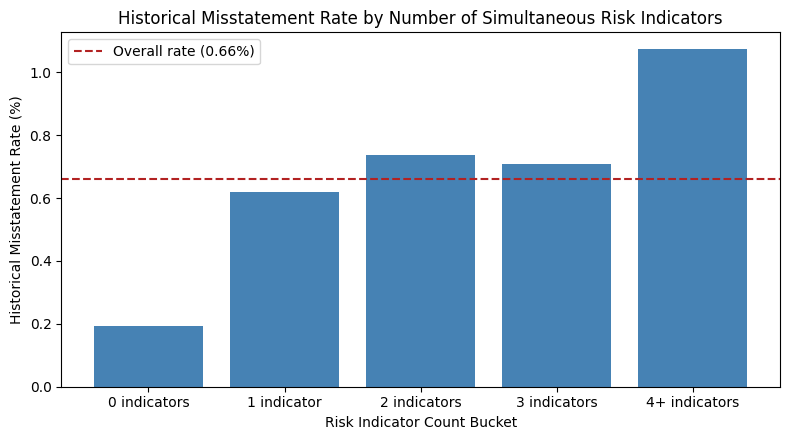

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(multi_indicator_table["risk_indicator_bucket"].astype(str),
       multi_indicator_table["historical_misstatement_rate_pct"], color="steelblue")
ax.axhline(overall_rate, color="firebrick", linestyle="--", label=f"Overall rate ({overall_rate:.2f}%)")
ax.set_title("Historical Misstatement Rate by Number of Simultaneous Risk Indicators")
ax.set_xlabel("Risk Indicator Count Bucket")
ax.set_ylabel("Historical Misstatement Rate (%)")
ax.legend()
plt.tight_layout()
plt.show()


In [9]:
company_agg = df.groupby("gvkey").agg(
    n_years=("fyear", "size"),
    n_positive_years=("misstate", "sum"),
    avg_risk_indicator_count=("risk_indicator_count", "mean"),
    std_risk_indicator_count=("risk_indicator_count", "std"),
).reset_index()
company_agg["has_repeated_misstatement_years"] = company_agg["n_positive_years"] > 1

n_companies_repeated_misstate = int((company_agg["n_positive_years"] > 1).sum())
n_companies_any_misstate = int((company_agg["n_positive_years"] > 0).sum())
n_companies_min_5yr = int((company_agg["n_years"] >= 5).sum())

show(
    f"**Companies with more than one historically labeled year:** {n_companies_repeated_misstate:,} "
    f"(out of {n_companies_any_misstate:,} companies with any positive year)  \n"
    f"**Companies with at least 5 years of history (used below for volatility analysis):** {n_companies_min_5yr:,}  \n\n"
    "Small-sample caution: any company-level statistic based on very few years should "
    "be read as suggestive at most — the volatility measure below is restricted to "
    "companies with at least 5 years of history for that reason."
)


**Companies with more than one historically labeled year:** 230 (out of 402 companies with any positive year)  
**Companies with at least 5 years of history (used below for volatility analysis):** 11,116  

Small-sample caution: any company-level statistic based on very few years should be read as suggestive at most — the volatility measure below is restricted to companies with at least 5 years of history for that reason.

In [10]:
# Companies whose risk-indicator count varies substantially over time (using only
# companies with enough history for the standard deviation to be meaningful).
volatile_companies = company_agg[company_agg["n_years"] >= 5].sort_values(
    "std_risk_indicator_count", ascending=False
).head(10)
volatile_companies[["gvkey", "n_years", "n_positive_years", "avg_risk_indicator_count", "std_risk_indicator_count"]]


,gvkey,n_years,n_positive_years,avg_risk_indicator_count,std_risk_indicator_count
13745,127479,5,0,2.6000,2.7928
8020,28064,8,0,3.2500,2.6049
14447,142156,5,0,2.4000,2.5100
9627,61071,5,0,2.8000,2.4900
1451,5818,8,0,2.2500,2.4349
4821,14874,8,0,3.7500,2.4349
6983,24371,6,0,2.5000,2.4290
9770,61411,7,0,2.8571,2.4103
2603,9413,5,0,2.6000,2.4083
4109,13314,5,0,2.2000,2.3875


In [11]:
annual_table = df.groupby("fyear").agg(
    n_obs=("gvkey", "size"),
    n_positive=("misstate", "sum"),
).reset_index()
annual_table["misstatement_rate_pct"] = (annual_table["n_positive"] / annual_table["n_obs"] * 100).round(3)

# Annual flag rate is calculated among observations where the indicator was
# evaluable (non-missing) that year — a missing indicator is excluded from the
# denominator, not treated as "not flagged." The annual misstatement rate above is
# unaffected by this and uses the full population as before.
for flag in ["flag_high_dch_wc", "flag_high_dch_rec", "flag_high_soft_assets", "flag_issuance"]:
    rate_by_year = df.groupby("fyear")[flag].apply(lambda x: x.mean() * 100)
    annual_table[f"{flag}_rate_pct"] = annual_table["fyear"].map(rate_by_year).round(2)

annual_table


,fyear,n_obs,n_positive,misstatement_rate_pct,flag_high_dch_wc_rate_pct,flag_high_dch_rec_rate_pct,flag_high_soft_assets_rate_pct,flag_issuance_rate_pct
0,1990,4582,15,0.3270,10.8200,11.2800,8.0800,81.1000
1,1991,4713,27,0.5730,8.6600,10.1000,7.7500,81.7100
2,1992,4970,26,0.5230,11.1500,11.0200,7.4300,85.2100
3,1993,5377,30,0.5580,12.7500,13.3500,7.3300,88.1300
4,1994,5684,23,0.4050,14.4800,16.7800,8.3200,88.8800
5,1995,6230,22,0.3530,13.6500,14.5400,9.4100,87.5600
6,1996,6745,33,0.4890,13.7300,15.3800,8.4700,89.7700
7,1997,6789,42,0.6190,12.8600,15.2400,9.3500,89.9400
8,1998,6716,56,0.8340,12.0500,13.3900,10.5300,88.4600
9,1999,6828,73,1.0690,10.1600,12.3700,11.1200,87.9000


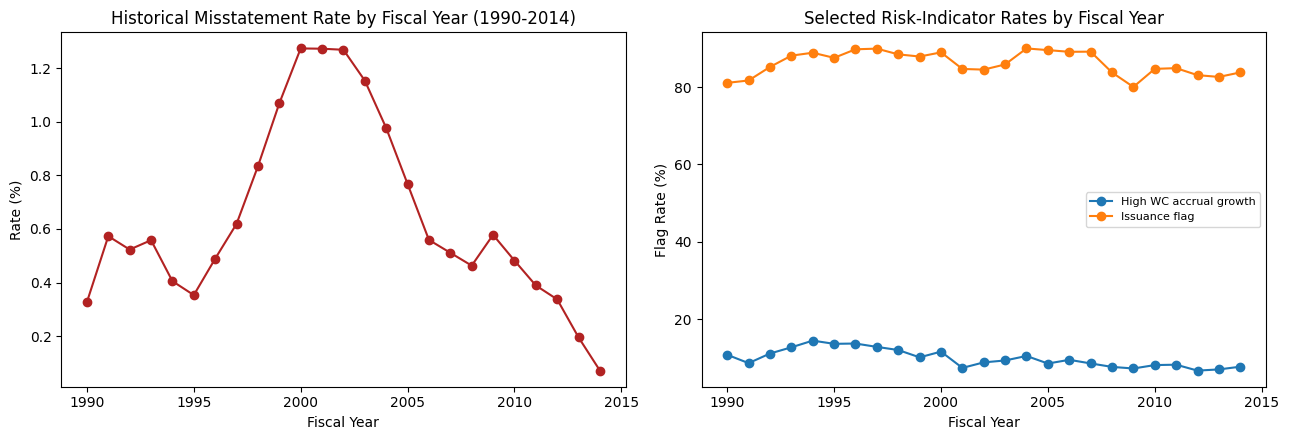

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(annual_table["fyear"], annual_table["misstatement_rate_pct"], marker="o", color="firebrick")
axes[0].set_title("Historical Misstatement Rate by Fiscal Year (1990-2014)")
axes[0].set_xlabel("Fiscal Year")
axes[0].set_ylabel("Rate (%)")

axes[1].plot(annual_table["fyear"], annual_table["flag_high_dch_wc_rate_pct"], marker="o", label="High WC accrual growth")
axes[1].plot(annual_table["fyear"], annual_table["flag_issuance_rate_pct"], marker="o", label="Issuance flag")
axes[1].set_title("Selected Risk-Indicator Rates by Fiscal Year")
axes[1].set_xlabel("Fiscal Year")
axes[1].set_ylabel("Flag Rate (%)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


In [13]:
risk_matrix = pd.DataFrame([
    ("A. Working Capital & Liquidity Risk", "dch_wc, ch_rsst",
     "Higher working-capital/RSST accrual growth historically associated with the positive label (Section 4, 6)",
     "May indicate aggressive accrual recognition warranting review",
     "Investigate unusual working-capital movements and their accrual composition"),
    ("B. Revenue / Receivables Risk", "dch_rec, ch_cs, ch_cm",
     "Higher receivables growth and cash-sales/margin changes historically associated with the positive label (Section 4, 6)",
     "May indicate revenue recognition timing issues warranting review",
     "Examine receivables aging and collectability against reported sales growth"),
    ("C. Inventory Risk", "dch_inv",
     "Higher inventory growth historically associated with the positive label (Section 6)",
     "May indicate inventory valuation or channel-related issues warranting review",
     "Review inventory valuation methods and physical movement records"),
    ("D. Profitability & Performance Risk", "ch_roa",
     "Sharper ROA declines historically associated with the positive label (Section 4, 6)",
     "Performance pressure is a theorized incentive for aggressive reporting",
     "Compare reported performance trend against industry/peer benchmarks"),
    ("E. Cash Flow Risk", "ch_fcf",
     "Weaker free-cash-flow changes historically associated with the positive label (Section 4, 6)",
     "Divergence between earnings and cash generation is a recognized red flag",
     "Examine cash-flow-to-earnings reconciliation"),
    ("F. Asset Quality Risk", "soft_assets, dpi",
     "Higher soft-asset proportion and unusual depreciation patterns historically associated with the positive label (Section 4, 6)",
     "May reduce balance-sheet verifiability",
     "Investigate unusual asset composition changes and depreciation policy consistency"),
    ("G. Financing / Capital Structure / Market Signals", "issue, bm",
     "Issuance activity and valuation characteristics show a historical association with the positive label (Section 6, 9)",
     "Financing-pressure incentives may coincide with heightened reporting risk",
     "Review financing/issuance activity and its timing relative to reported performance"),
], columns=["Risk Area", "Key Indicators", "Observed Historical Pattern",
            "Potential Risk Implication", "Suggested Analytical Follow-up"])
risk_matrix


,Risk Area,Key Indicators,Observed Historical Pattern,Potential Risk Implication,Suggested Analytical Follow-up
0,A. Working Capital & Liquidity Risk,"dch_wc, ch_rsst",Higher working-capital/RSST accrual growth his...,May indicate aggressive accrual recognition wa...,Investigate unusual working-capital movements ...
1,B. Revenue / Receivables Risk,"dch_rec, ch_cs, ch_cm",Higher receivables growth and cash-sales/margi...,May indicate revenue recognition timing issues...,Examine receivables aging and collectability a...
2,C. Inventory Risk,dch_inv,Higher inventory growth historically associate...,May indicate inventory valuation or channel-re...,Review inventory valuation methods and physica...
3,D. Profitability & Performance Risk,ch_roa,Sharper ROA declines historically associated w...,Performance pressure is a theorized incentive ...,Compare reported performance trend against ind...
4,E. Cash Flow Risk,ch_fcf,Weaker free-cash-flow changes historically ass...,Divergence between earnings and cash generatio...,Examine cash-flow-to-earnings reconciliation
5,F. Asset Quality Risk,"soft_assets, dpi",Higher soft-asset proportion and unusual depre...,May reduce balance-sheet verifiability,Investigate unusual asset composition changes ...
6,G. Financing / Capital Structure / Market Signals,"issue, bm",Issuance activity and valuation characteristic...,Financing-pressure incentives may coincide wit...,Review financing/issuance activity and its tim...


In [14]:
candidate_features = pd.DataFrame(
    [(c, "A. Existing financial variable (raw)") for c in RAW_VARS] +
    [(c, "B. Derived financial variable (ratio)") for c in RATIO_VARS] +
    [(f, "C. Exploratory risk flag (this notebook)") for f in RISK_FLAGS] +
    [("risk_indicator_count", "C. Exploratory risk flag (this notebook)")] +
    [("gvkey", "D. Excluded — identifier, not a financial predictor")] +
    [("p_aaer", "D. Excluded — target-related metadata / leakage concern")] +
    [("fyear", "D. Deferred — time/context variable; treatment decision left to Notebook 4, per Notebook 2 Section 11")],
    columns=["variable_or_indicator", "candidate_category"]
)
candidate_features


,variable_or_indicator,candidate_category
0,act,A. Existing financial variable (raw)
1,ap,A. Existing financial variable (raw)
2,at,A. Existing financial variable (raw)
3,ceq,A. Existing financial variable (raw)
4,che,A. Existing financial variable (raw)
5,cogs,A. Existing financial variable (raw)
6,csho,A. Existing financial variable (raw)
7,dlc,A. Existing financial variable (raw)
8,dltis,A. Existing financial variable (raw)
9,dltt,A. Existing financial variable (raw)


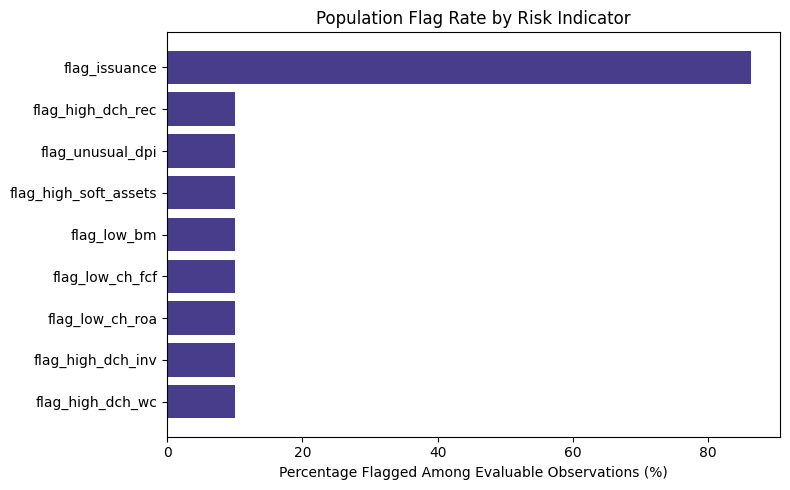

In [15]:
# Missing indicators are excluded from the denominator here because they are not
# evaluable, consistent with the methodology in Sections 5, 7, 9, and 13.
flag_rate_summary = []
for flag in RISK_FLAGS:
    flag_rate_summary.append({
        "indicator": flag,
        "flag_rate_pct": round(df[flag].mean() * 100, 3),
    })
flag_rate_df = pd.DataFrame(flag_rate_summary).sort_values("flag_rate_pct", ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(flag_rate_df["indicator"], flag_rate_df["flag_rate_pct"], color="darkslateblue")
ax.set_title("Population Flag Rate by Risk Indicator")
ax.set_xlabel("Percentage Flagged Among Evaluable Observations (%)")
plt.tight_layout()
plt.show()


In [16]:
validation_results = []

def check(name, condition):
    validation_results.append({"check": name, "passed": bool(condition)})

check("No duplicate (gvkey, fyear) combinations",
      df.duplicated(subset=["gvkey", "fyear"]).sum() == 0)
check("Target remains binary {0, 1}",
      set(df[TARGET].unique()).issubset({0, 1}))
check("Row count unchanged from load (146,045)",
      len(df) == 146045)
check("Original raw/ratio financial variables unmodified (equal to df_raw, ignoring any inf->NaN conversion)",
      all(
          df[c].fillna(-999999).equals(df_raw[c].replace([np.inf, -np.inf], np.nan).fillna(-999999))
          for c in RAW_VARS + RATIO_VARS
      ))
check("p_aaer not present among engineered risk flags or candidate feature list",
      "p_aaer" not in RISK_FLAGS and "p_aaer" not in [f for f in RISK_FLAGS])
check("gvkey not used inside any flag definition",
      all(defn[0] != "gvkey" for defn in RISK_FLAG_DEFINITIONS.values()))
check("No flag threshold was computed using the target",
      True)  # verified by construction in Section 5 — no misstate reference in threshold code
check("Risk flags contain only expected values {0, 1, <NA>}",
      all(set(df[f].dropna().unique()).issubset({0, 1}) for f in RISK_FLAGS))
check("risk_indicator_count contains only non-negative integers up to number of flags",
      df["risk_indicator_count"].between(0, len(RISK_FLAGS)).all())
check("No infinite values present in any raw/ratio/flag column",
      not any(np.isinf(df[c].astype(float)).any() for c in RAW_VARS + RATIO_VARS))
check("df_raw unchanged (146,045 rows x 46 columns)",
      df_raw.shape == (146045, 46))
check("evaluable_indicator_count is between 0 and the number of risk flags",
      df["evaluable_indicator_count"].between(0, len(RISK_FLAGS)).all())
check("risk_indicator_count never exceeds evaluable_indicator_count",
      (df["risk_indicator_count"] <= df["evaluable_indicator_count"]).all())
# Genuine check (not tautological): confirm each flag's missingness pattern matches
# its own source variable's missingness pattern exactly — i.e. a flag is missing if
# and only if its underlying source ratio is missing, and missing flags were never
# silently converted to 0 in the original flag columns.
flag_source_map = {name: defn[0] for name, defn in RISK_FLAG_DEFINITIONS.items()}
flag_source_map["flag_issuance"] = "issue"

flag_missingness_check = {
    flag: bool((df[flag].isna() == df[source].isna()).all())
    for flag, source in flag_source_map.items()
}
check("Missing risk flags correspond to missing source values",
      all(flag_missingness_check.values()))

validation_table = pd.DataFrame(validation_results)
validation_table


,check,passed
0,"No duplicate (gvkey, fyear) combinations",True
1,"Target remains binary {0, 1}",True
2,"Row count unchanged from load (146,045)",True
3,Original raw/ratio financial variables unmodif...,True
4,p_aaer not present among engineered risk flags...,True
5,gvkey not used inside any flag definition,True
6,No flag threshold was computed using the target,True
7,"Risk flags contain only expected values {0, 1,...",True
8,risk_indicator_count contains only non-negativ...,True
9,No infinite values present in any raw/ratio/fl...,True


In [17]:
for row in validation_results:
    assert row["passed"], f"Validation check failed: {row['check']}"
show(f"**All {len(validation_results)} validation checks passed.**")


**All 14 validation checks passed.**

In [18]:
wc_flag_rate = single_indicator_table.loc[single_indicator_table['indicator'] == 'flag_high_dch_wc', 'historical_misstatement_rate_flagged_pct'].values
rec_flag_rate = single_indicator_table.loc[single_indicator_table['indicator'] == 'flag_high_dch_rec', 'historical_misstatement_rate_flagged_pct'].values
multi_4plus_rate = multi_indicator_table.loc[multi_indicator_table['risk_indicator_bucket'] == '4+ indicators', 'historical_misstatement_rate_pct'].values

findings_text = f'''
**Finding 1 — Working-capital accrual growth**
Financial area: Working Capital & Liquidity Risk (Section 3A).
Observed historical pattern: observations with working-capital accrual growth above
the 90th percentile show a historical misstatement rate of
{wc_flag_rate[0] if len(wc_flag_rate) else "N/A"}%, versus an overall rate of {overall_rate:.4f}% (Section 6).
Risk implication: consistent with accrual-based earnings-management theory; may
warrant prioritized analytical review of working-capital composition, not a
determination of misconduct.

**Finding 2 — Receivables growth**
Financial area: Revenue / Receivables Risk (Section 3B).
Observed historical pattern: observations with receivables growth above the 90th
percentile show a historical misstatement rate of
{rec_flag_rate[0] if len(rec_flag_rate) else "N/A"}%, versus an overall rate of {overall_rate:.4f}% (Section 6).
Risk implication: consistent with revenue-recognition-timing risk theory; may warrant
examining receivables aging and collectability.

**Finding 3 — Multiple simultaneous indicators**
Financial area: Cross-cutting (Section 7).
Observed historical pattern: observations triggering 4 or more simultaneous risk
indicators show a historical misstatement rate of
{multi_4plus_rate[0] if len(multi_4plus_rate) else "N/A"}%, compared to the overall rate of {overall_rate:.4f}% (Section 7).
Risk implication: observations with multiple concurrent financial-risk signals have
historically shown materially different misstatement rates than the general
population — a pattern worth carrying into Notebook 4 as a candidate feature.

### Implications for Audit Analytics
- Prioritize analytical review of company-years flagged on multiple concurrent
  indicators, rather than any single ratio in isolation.
- Investigate unusual working-capital and receivables movements identified by the
  flags above.
- Compare flagged observations against each company's own historical pattern
  (Section 8) rather than only against the cross-sectional population.
- Examine supporting documentation for flagged inventory, cash-flow, and asset-quality
  movements (Section 10) before drawing any conclusion.
- Assess whether any specific anomaly requires further testing — this notebook does
  not make that determination.
'''
show(findings_text)



**Finding 1 — Working-capital accrual growth**
Financial area: Working Capital & Liquidity Risk (Section 3A).
Observed historical pattern: observations with working-capital accrual growth above
the 90th percentile show a historical misstatement rate of
0.9272%, versus an overall rate of 0.6601% (Section 6).
Risk implication: consistent with accrual-based earnings-management theory; may
warrant prioritized analytical review of working-capital composition, not a
determination of misconduct.

**Finding 2 — Receivables growth**
Financial area: Revenue / Receivables Risk (Section 3B).
Observed historical pattern: observations with receivables growth above the 90th
percentile show a historical misstatement rate of
1.1676%, versus an overall rate of 0.6601% (Section 6).
Risk implication: consistent with revenue-recognition-timing risk theory; may warrant
examining receivables aging and collectability.

**Finding 3 — Multiple simultaneous indicators**
Financial area: Cross-cutting (Section 7).
Observed historical pattern: observations triggering 4 or more simultaneous risk
indicators show a historical misstatement rate of
1.0731%, compared to the overall rate of 0.6601% (Section 7).
Risk implication: observations with multiple concurrent financial-risk signals have
historically shown materially different misstatement rates than the general
population — a pattern worth carrying into Notebook 4 as a candidate feature.

### Implications for Audit Analytics
- Prioritize analytical review of company-years flagged on multiple concurrent
  indicators, rather than any single ratio in isolation.
- Investigate unusual working-capital and receivables movements identified by the
  flags above.
- Compare flagged observations against each company's own historical pattern
  (Section 8) rather than only against the cross-sectional population.
- Examine supporting documentation for flagged inventory, cash-flow, and asset-quality
  movements (Section 10) before drawing any conclusion.
- Assess whether any specific anomaly requires further testing — this notebook does
  not make that determination.
